# 05. What the models select, and why

Sparse models produce a list of selected indicators at every origin. Because the list changes with the
sample (learn/08), we report **selection frequencies**: the share of the 82 backtest origins (33 at
horizon 3) in which each indicator has at least one non-zero lag. The origins include the six COVID
quarters, which are nowcast (from pre-COVID training data) but excluded from the accuracy tables.

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from nowcast.config import HORIZON_LABELS

In [2]:
sel = pd.read_csv(T / "selection_frequency.csv")
for m in ["Lasso", "Group lasso"]:
    s = sel[(sel.model == m) & (sel.h == 2)].head(12)
    print(f"{m}, end-of-quarter nowcasts (n origins = {s.n_origins.iloc[0]})")
    display(s[["code", "name", "group", "frequency"]].round(2).set_index("code"))

Lasso, end-of-quarter nowcasts (n origins = 82)


,name,group,frequency
code,,,
IUMABEDR,Bank Rate,Money and markets,1.00
RT_IOP,Index of Production (real time),Output (real time),0.90
AP2Y,Vacancies,Labour market,0.85
RT_IOS,Index of Services (real time),Output (real time),0.85
GDP_q1,"GDP growth, quarter t-1",GDP,0.84
LPMAUYN,M4 money supply,Money and markets,0.84
MGSX,Unemployment rate,Labour market,0.80
XUMAUSS,Sterling-dollar rate,Money and markets,0.78
MGRZ,Employment level,Labour market,0.78


Group lasso, end-of-quarter nowcasts (n origins = 82)


,name,group,frequency
code,,,
IUMABEDR,Bank Rate,Money and markets,0.98
GDP_q1,"GDP growth, quarter t-1",GDP,0.87
XUMAUSS,Sterling-dollar rate,Money and markets,0.87
MGSX,Unemployment rate,Labour market,0.87
IUMBV34,2-year fixed mortgage rate (75% LTV),Money and markets,0.87
RT_IOS,Index of Services (real time),Output (real time),0.85
LPMAUYN,M4 money supply,Money and markets,0.85
MGRZ,Employment level,Labour market,0.84
AP2Y,Vacancies,Labour market,0.83


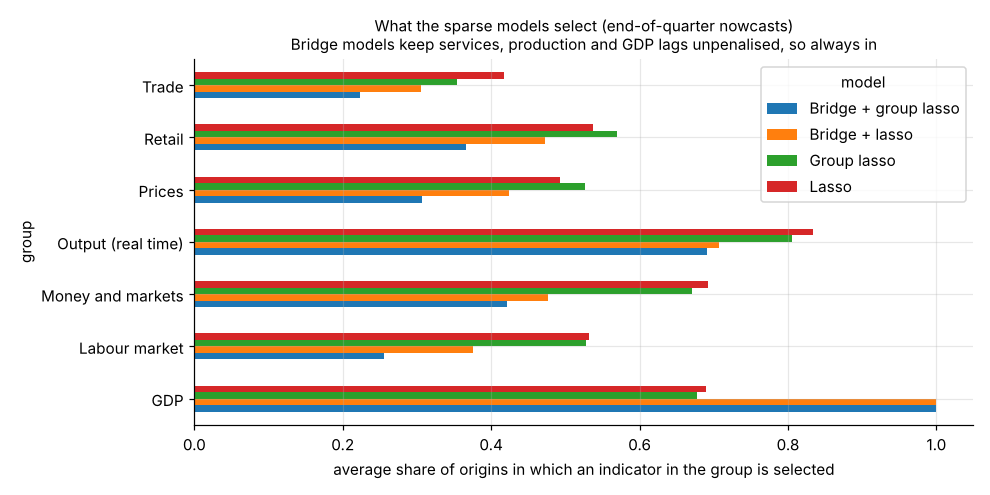

In [3]:
display(Image(FIG / 'selection_by_group_h2.png'))

In [4]:
s = sel[sel.model == "Lasso"]
stab = s.groupby("h").frequency.agg(always=lambda f: (f >= 0.9).sum(), sometimes=lambda f: ((f > 0.1) & (f < 0.9)).sum(),
                                     rarely=lambda f: (f <= 0.1).sum())
print("Lasso: number of indicators selected in >=90%, 10-90%, <=10% of origins")
stab.rename(index=HORIZON_LABELS)

Lasso: number of indicators selected in >=90%, 10-90%, <=10% of origins


,always,sometimes,rarely
h,,,
Before quarter,2,32,42
End of month 1,1,33,42
End of month 2,1,39,36
End of month 3,2,39,35
Month after quarter,17,21,38


## Contributions to the live nowcast
For a linear model on standardised features, the nowcast is the intercept plus the sum of
coefficient x feature. Summing within indicator groups shows which data move the nowcast away from
the model's baseline.

In [5]:
c = pd.read_csv(T / "live_contributions.csv")
for q in sorted(c.quarter.unique()):
    t = c[(c.quarter == q) & c.model.isin(["Bridge", "Ridge", "Group lasso", "Bridge + ridge", "Bridge + group lasso"])]
    print(q); display(t.pivot(index="group", columns="model", values="contribution").round(3))

2026Q3


model,Bridge,Bridge + group lasso,Bridge + ridge,Group lasso,Ridge
group,,,,,
GDP,0.040,0.036,0.040,0.016,0.010
Labour market,0.000,0.000,-0.021,-0.010,-0.138
Manufacturing detail (latest vintage),0.000,0.000,0.000,0.000,0.000
Money and markets,0.000,-0.004,-0.058,-0.051,-0.080
Output (latest vintage),0.000,0.000,0.000,0.000,0.000
Output (real time),0.247,0.294,0.240,0.175,0.138
Prices,0.000,0.000,-0.037,-0.007,-0.007
Retail,0.000,0.001,0.027,0.048,0.028
Trade,0.000,0.000,-0.033,-0.004,-0.026


2026Q4


model,Bridge,Bridge + group lasso,Bridge + ridge,Group lasso,Ridge
group,,,,,
GDP,-0.001,-0.001,-0.001,0.000,0.002
Labour market,0.000,0.000,0.002,-0.085,-0.003
Manufacturing detail (latest vintage),0.000,0.000,0.000,0.000,0.000
Money and markets,0.000,-0.000,0.003,-0.031,-0.020
Output (latest vintage),0.000,0.000,0.000,0.000,0.000
Output (real time),0.123,0.123,0.122,-0.024,0.047
Prices,0.000,0.000,0.001,-0.101,0.017
Retail,0.000,0.000,-0.002,0.000,0.005
Trade,0.000,0.000,-0.010,-0.024,-0.010
